In [15]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("demandsense_consistent.csv")
df["date"] = pd.to_datetime(df["date"])

hotel_id = "H001"

hotel_df = df[df["hotel_id"] == hotel_id].copy()
hotel_df = hotel_df.sort_values("date").reset_index(drop=True)

hotel_df["occupancy_lag_1"] = hotel_df["occupancy_rate"].shift(1)

hotel_df["occupancy_lag_7"] = (
    hotel_df["occupancy_rate"].shift(1).rolling(7).mean()
)

hotel_df = hotel_df.dropna().reset_index(drop=True)

features = [
    "month", "day", "day_of_year",
    "is_weekend", "is_holiday",
    "occupancy_lag_1", "occupancy_lag_7"
]

X = hotel_df[features]
y = hotel_df["occupancy_rate"]

split_index = int(len(hotel_df) * 0.8)

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

model.fit(X_train, y_train)

print("XGBoost model trained successfully!")
print("Hotel:", hotel_id)
print("Total records:", len(hotel_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

XGBoost model trained successfully!
Hotel: H001
Total records: 1374
Training records: 1099
Testing records: 275


In [16]:
history = hotel_df["occupancy_rate"].tolist()
last_date = hotel_df["date"].max()

total_rooms = int(
    df.loc[df["hotel_id"] == hotel_id, "total_rooms"].iloc[0]
)

future_rows = []

for i in range(1, 8):
    future_date = last_date + pd.Timedelta(days=i)

    lag_1 = history[-1]
    lag_7 = np.mean(history[-7:])

    future_input = pd.DataFrame([{
        "month": future_date.month,
        "day": future_date.day,
        "day_of_year": future_date.dayofyear,
        "is_weekend": int(future_date.dayofweek >= 5),
        "is_holiday": 0,
        "occupancy_lag_1": lag_1,
        "occupancy_lag_7": lag_7
    }])[features]

    prediction = float(model.predict(future_input)[0])
    prediction = float(np.clip(prediction, 0, 100))

    occupied = round(total_rooms * prediction / 100)
    vacant = total_rooms - occupied

    future_rows.append({
        "date": future_date,
        "predicted_occupancy": round(prediction, 2),
        "total_rooms": total_rooms,
        "predicted_occupied_rooms": occupied,
        "predicted_vacant_rooms": vacant
    })

    history.append(prediction)

forecast = pd.DataFrame(future_rows)

print(forecast.to_string(index=False))

      date  predicted_occupancy  total_rooms  predicted_occupied_rooms  predicted_vacant_rooms
2026-10-13                50.39           80                        40                      40
2026-10-14                50.18           80                        40                      40
2026-10-15                50.18           80                        40                      40
2026-10-16                50.18           80                        40                      40
2026-10-17                70.30           80                        56                      24
2026-10-18                71.73           80                        57                      23
2026-10-19                50.56           80                        40                      40


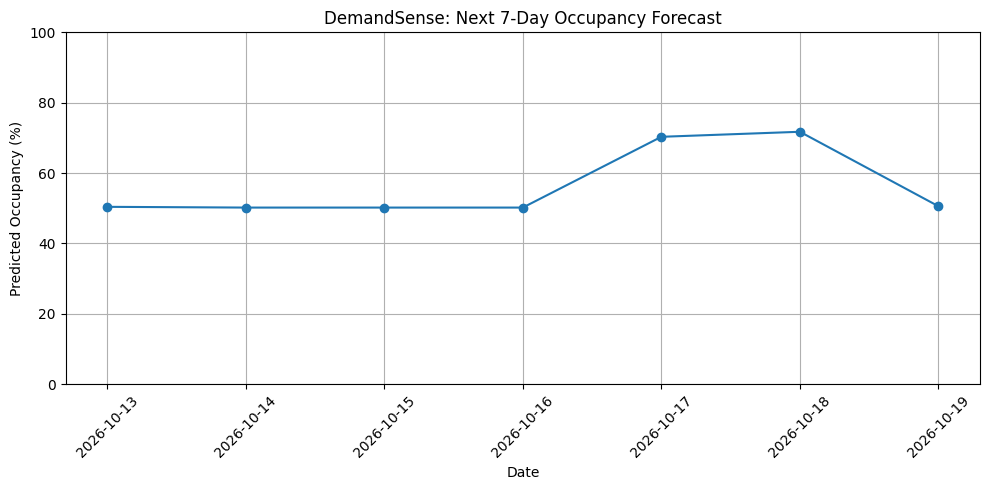

In [17]:

plt.figure(figsize=(10, 5))

plt.plot(
    forecast["date"],
    forecast["predicted_occupancy"],
    marker="o"
)

plt.title("DemandSense: Next 7-Day Occupancy Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Occupancy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:

def get_demand_level(occupancy):
    if occupancy >= 75:
        return "High Demand"
    elif occupancy < 40:
        return "Low Demand"
    else:
        return "Normal Demand"

forecast["demand_level"] = forecast["predicted_occupancy"].apply(
    get_demand_level
)

print(forecast)


        date  predicted_occupancy  total_rooms  predicted_occupied_rooms  \
0 2026-10-13                50.39           80                        40   
1 2026-10-14                50.18           80                        40   
2 2026-10-15                50.18           80                        40   
3 2026-10-16                50.18           80                        40   
4 2026-10-17                70.30           80                        56   
5 2026-10-18                71.73           80                        57   
6 2026-10-19                50.56           80                        40   

   predicted_vacant_rooms   demand_level  
0                      40  Normal Demand  
1                      40  Normal Demand  
2                      40  Normal Demand  
3                      40  Normal Demand  
4                      24  Normal Demand  
5                      23  Normal Demand  
6                      40  Normal Demand  


In [19]:

def get_recommendation(level):
    if level == "High Demand":
        return "Prepare extra staff, check inventory, review pricing"
    elif level == "Low Demand":
        return "Offer promotions, reduce unnecessary stock orders"
    else:
        return "Maintain normal staffing and monitor bookings"

forecast["recommendation"] = forecast["demand_level"].apply(
    get_recommendation
)

print(forecast.to_string(index=False))


      date  predicted_occupancy  total_rooms  predicted_occupied_rooms  predicted_vacant_rooms  demand_level                                recommendation
2026-10-13                50.39           80                        40                      40 Normal Demand Maintain normal staffing and monitor bookings
2026-10-14                50.18           80                        40                      40 Normal Demand Maintain normal staffing and monitor bookings
2026-10-15                50.18           80                        40                      40 Normal Demand Maintain normal staffing and monitor bookings
2026-10-16                50.18           80                        40                      40 Normal Demand Maintain normal staffing and monitor bookings
2026-10-17                70.30           80                        56                      24 Normal Demand Maintain normal staffing and monitor bookings
2026-10-18                71.73           80                        57

In [20]:

print("Forecast statistics:")
print(forecast["predicted_occupancy"].describe())

print("\nPredicted occupancy range:")
print(
    forecast["predicted_occupancy"].min(),
    "to",
    forecast["predicted_occupancy"].max()
)

print("\nDemand-level counts:")
print(forecast["demand_level"].value_counts())


Forecast statistics:
count     7.000000
mean     56.217143
std      10.118265
min      50.180000
25%      50.180000
50%      50.390000
75%      60.430000
max      71.730000
Name: predicted_occupancy, dtype: float64

Predicted occupancy range:
50.18 to 71.73

Demand-level counts:
demand_level
Normal Demand    7
Name: count, dtype: int64


In [21]:
xgb_predictions = np.clip(model.predict(X_test), 0, 100)

print("One-step test predictions created successfully!")
print("MAE:", round(mean_absolute_error(y_test, xgb_predictions), 2))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, xgb_predictions)), 2)
)

One-step test predictions created successfully!
MAE: 5.73
RMSE: 7.2


In [22]:

# Use the XGBoost test predictions
errors = xgb_predictions - y_test.to_numpy()

print("Mean prediction error:", round(errors.mean(), 2))
print("Mean absolute error:", round(np.abs(errors).mean(), 2))

if errors.mean() > 1:
    print("The model tends to overpredict occupancy.")
elif errors.mean() < -1:
    print("The model tends to underpredict occupancy.")
else:
    print("There is little overall average prediction bias.")


Mean prediction error: 0.2
Mean absolute error: 5.73
There is little overall average prediction bias.


In [23]:

check = hotel_df.iloc[split_index:].copy()

check["actual_occupancy"] = y_test.to_numpy()
check["predicted_occupancy"] = xgb_predictions

check["day_type"] = check["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

print(
    check.groupby("day_type")[
        ["actual_occupancy", "predicted_occupancy"]
    ].mean().round(2)
)


          actual_occupancy  predicted_occupancy
day_type                                       
Weekday              53.30            53.630001
Weekend              70.98            70.879997


In [24]:

# Group actual occupancy into demand categories
check["actual_demand"] = pd.cut(
    check["actual_occupancy"],
    bins=[-1, 40, 75, 100],
    labels=["Low", "Normal", "High"]
)

print(
    check.groupby("actual_demand", observed=False)[
        ["actual_occupancy", "predicted_occupancy"]
    ].mean().round(2)
)


               actual_occupancy  predicted_occupancy
actual_demand                                       
Low                       35.82            43.730000
Normal                    57.03            56.470001
High                      83.65            79.769997


In [25]:

# Assign demand categories to actual and predicted occupancy
check["predicted_demand"] = pd.cut(
    check["predicted_occupancy"],
    bins=[-1, 40, 75, 100],
    labels=["Low", "Normal", "High"]
)

# Compare actual vs predicted demand categories
comparison = pd.crosstab(
    check["actual_demand"],
    check["predicted_demand"],
    rownames=["Actual Demand"],
    colnames=["Predicted Demand"]
)

print(comparison)


Predicted Demand  Low  Normal  High
Actual Demand                      
Low                 2      42     0
Normal              3     164    15
High                0       8    41


In [14]:

print("Training occupancy statistics:")
print(y_train.describe().round(2))

print("\nNumber of training days in each category:")
print(
    pd.cut(
        y_train,
        bins=[-1, 40, 75, 100],
        labels=["Low", "Normal", "High"]
    ).value_counts().sort_index()
)


Training occupancy statistics:
count    1099.00
mean       59.95
std        15.58
min        20.51
25%        47.50
50%        58.75
75%        71.34
max        97.50
Name: occupancy_rate, dtype: float64

Number of training days in each category:
occupancy_rate
Low       113
Normal    783
High      203
Name: count, dtype: int64


In [26]:
backtest_rows = []

test_start = split_index
test_end = len(hotel_df)

for start in range(test_start, test_end - 6, 7):
    history = hotel_df["occupancy_rate"].iloc[:start].tolist()

    for step in range(7):
        row_index = start + step
        actual_date = hotel_df.loc[row_index, "date"]

        future_input = pd.DataFrame([{
            "month": actual_date.month,
            "day": actual_date.day,
            "day_of_year": actual_date.dayofyear,
            "is_weekend": int(actual_date.dayofweek >= 5),
            "is_holiday": int(hotel_df.loc[row_index, "is_holiday"]),
            "occupancy_lag_1": history[-1],
            "occupancy_lag_7": np.mean(history[-7:])
        }])[features]

        predicted = float(model.predict(future_input)[0])
        predicted = float(np.clip(predicted, 0, 100))
        actual = float(hotel_df.loc[row_index, "occupancy_rate"])

        backtest_rows.append({
            "date": actual_date,
            "day_ahead": step + 1,
            "actual_occupancy": actual,
            "predicted_occupancy": predicted
        })

        # Use the prediction, not actual occupancy, for the next day
        history.append(predicted)

backtest = pd.DataFrame(backtest_rows)

print("Seven-day recursive backtest")
print("Days evaluated:", len(backtest))

print(
    "Overall MAE:",
    round(
        mean_absolute_error(
            backtest["actual_occupancy"],
            backtest["predicted_occupancy"]
        ),
        2
    )
)

print("\nMAE by forecast day:")

for day in range(1, 8):
    day_data = backtest[backtest["day_ahead"] == day]

    if len(day_data) > 0:
        day_mae = mean_absolute_error(
            day_data["actual_occupancy"],
            day_data["predicted_occupancy"]
        )
        print("Day", day, "MAE:", round(day_mae, 2))

Seven-day recursive backtest
Days evaluated: 273
Overall MAE: 5.75

MAE by forecast day:
Day 1 MAE: 5.44
Day 2 MAE: 6.34
Day 3 MAE: 5.88
Day 4 MAE: 5.49
Day 5 MAE: 5.67
Day 6 MAE: 6.02
Day 7 MAE: 5.43


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

baseline_rows = []

test_start = split_index
test_end = len(hotel_df)

# Use the same seven-day forecast windows as our XGBoost backtest
for start in range(test_start, test_end - 6, 7):

    history = hotel_df["occupancy_rate"].iloc[:start].tolist()

    for step in range(7):

        row_index = start + step
        actual = float(hotel_df.loc[row_index, "occupancy_rate"])

        # Baseline predicts occupancy will stay at the last known value
        predicted = history[-1]

        baseline_rows.append({
            "date": hotel_df.loc[row_index, "date"],
            "day_ahead": step + 1,
            "actual_occupancy": actual,
            "predicted_occupancy": predicted
        })

        # Recursively use the baseline prediction for the next day
        history.append(predicted)

baseline_df = pd.DataFrame(baseline_rows)

baseline_mae_7d = mean_absolute_error(
    baseline_df["actual_occupancy"],
    baseline_df["predicted_occupancy"]
)

baseline_rmse_7d = np.sqrt(
    mean_squared_error(
        baseline_df["actual_occupancy"],
        baseline_df["predicted_occupancy"]
    )
)

print("Seven-Day Recursive Comparison")
print("--------------------------------")
print("XGBoost MAE:", round(
    mean_absolute_error(
        backtest["actual_occupancy"],
        backtest["predicted_occupancy"]
    ), 2
))
print("Baseline MAE:", round(baseline_mae_7d, 2))
print("XGBoost RMSE:", round(
    np.sqrt(mean_squared_error(
        backtest["actual_occupancy"],
        backtest["predicted_occupancy"]
    )), 2
))
print("Baseline RMSE:", round(baseline_rmse_7d, 2))

Seven-Day Recursive Comparison
--------------------------------
XGBoost MAE: 5.75
Baseline MAE: 15.76
XGBoost RMSE: 7.26
Baseline RMSE: 18.63


In [28]:
# 30-day recursive occupancy forecast

history = hotel_df["occupancy_rate"].tolist()
last_date = hotel_df["date"].max()

total_rooms = int(
    df.loc[df["hotel_id"] == hotel_id, "total_rooms"].iloc[0]
)

forecast_30 = []

for i in range(1, 31):
    future_date = last_date + pd.Timedelta(days=i)

    future_input = pd.DataFrame([{
        "month": future_date.month,
        "day": future_date.day,
        "day_of_year": future_date.dayofyear,
        "is_weekend": int(future_date.dayofweek >= 5),
        "is_holiday": 0,
        "occupancy_lag_1": history[-1],
        "occupancy_lag_7": np.mean(history[-7:])
    }])[features]

    prediction = float(model.predict(future_input)[0])
    prediction = float(np.clip(prediction, 0, 100))

    occupied = round(total_rooms * prediction / 100)
    vacant = total_rooms - occupied

    forecast_30.append({
        "date": future_date,
        "predicted_occupancy": round(prediction, 2),
        "total_rooms": total_rooms,
        "predicted_occupied_rooms": occupied,
        "predicted_vacant_rooms": vacant
    })

    history.append(prediction)

forecast_30 = pd.DataFrame(forecast_30)

print("30-Day Occupancy Forecast")
print(forecast_30.to_string(index=False))

forecast_30.to_csv("demandsense_30_day_forecast.csv", index=False)
print("\nSaved: demandsense_30_day_forecast.csv")

30-Day Occupancy Forecast
      date  predicted_occupancy  total_rooms  predicted_occupied_rooms  predicted_vacant_rooms
2026-10-13                50.39           80                        40                      40
2026-10-14                50.18           80                        40                      40
2026-10-15                50.18           80                        40                      40
2026-10-16                50.18           80                        40                      40
2026-10-17                70.30           80                        56                      24
2026-10-18                71.73           80                        57                      23
2026-10-19                50.56           80                        40                      40
2026-10-20                50.78           80                        41                      39
2026-10-21                50.63           80                        41                      39
2026-10-22              

In [29]:
# 30-day recursive backtest
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

backtest_30_rows = []

# Use non-overlapping 30-day windows in the test period
for start in range(split_index, len(hotel_df) - 29, 30):

    history = hotel_df["occupancy_rate"].iloc[:start].tolist()

    for step in range(30):
        row_index = start + step
        actual_date = hotel_df.loc[row_index, "date"]
        actual = float(hotel_df.loc[row_index, "occupancy_rate"])

        future_input = pd.DataFrame([{
            "month": actual_date.month,
            "day": actual_date.day,
            "day_of_year": actual_date.dayofyear,
            "is_weekend": int(actual_date.dayofweek >= 5),
            "is_holiday": int(hotel_df.loc[row_index, "is_holiday"]),
            "occupancy_lag_1": history[-1],
            "occupancy_lag_7": np.mean(history[-7:])
        }])[features]

        predicted = float(model.predict(future_input)[0])
        predicted = float(np.clip(predicted, 0, 100))

        baseline_predicted = history[-1]

        backtest_30_rows.append({
            "date": actual_date,
            "day_ahead": step + 1,
            "actual": actual,
            "xgboost_prediction": predicted,
            "baseline_prediction": baseline_predicted
        })

        # Both forecasts continue recursively using their own predictions
        history.append(predicted)

backtest_30 = pd.DataFrame(backtest_30_rows)

if backtest_30.empty:
    print("Not enough held-out data for a 30-day backtest window.")
else:
    xgb_mae_30 = mean_absolute_error(
        backtest_30["actual"],
        backtest_30["xgboost_prediction"]
    )
    baseline_mae_30 = mean_absolute_error(
        backtest_30["actual"],
        backtest_30["baseline_prediction"]
    )

    xgb_rmse_30 = np.sqrt(mean_squared_error(
        backtest_30["actual"],
        backtest_30["xgboost_prediction"]
    ))
    baseline_rmse_30 = np.sqrt(mean_squared_error(
        backtest_30["actual"],
        backtest_30["baseline_prediction"]
    ))

    print("30-Day Recursive Backtest")
    print("Evaluated predictions:", len(backtest_30))
    print("XGBoost MAE:", round(xgb_mae_30, 2))
    print("Baseline MAE:", round(baseline_mae_30, 2))
    print("XGBoost RMSE:", round(xgb_rmse_30, 2))
    print("Baseline RMSE:", round(baseline_rmse_30, 2))

    print("\nMAE by forecast horizon:")
    for day in [1, 7, 14, 21, 30]:
        subset = backtest_30[backtest_30["day_ahead"] == day]
        if not subset.empty:
            day_mae = mean_absolute_error(
                subset["actual"], subset["xgboost_prediction"]
            )
            print(f"Day {day}: {day_mae:.2f}")

30-Day Recursive Backtest
Evaluated predictions: 270
XGBoost MAE: 5.87
Baseline MAE: 9.67
XGBoost RMSE: 7.46
Baseline RMSE: 12.74

MAE by forecast horizon:
Day 1: 5.85
Day 7: 4.69
Day 14: 3.06
Day 21: 4.37
Day 30: 6.36
